<a href="https://colab.research.google.com/github/vivek-bhushan/vivek-bhushan-IITM-CAPSTONE_PROJECT/blob/main/01_data_preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 · Data Preparation — Phase 1
### Problem Framing and Dataset Preparation

**Project:** Intelligent Retail Decision Assistant (Capstone)
**Phase:** 1 of 5 — *choose the use case, inspect the data, clean it, engineer features, publish a data dictionary*

---

A mid-sized online retailer wants one AI system that can (a) analyse customer and product
behaviour with **classical machine learning**, (b) answer product questions with **retrieval-backed
generative AI**, and (c) answer policy questions with **grounded, cited evidence**. This first
notebook fixes the business frame and produces the single clean, documented dataset that every
later phase consumes.

> **Why this notebook matters.** Everything downstream — the ML pipeline (Phase 2), the retrieval
> documents (Phase 3), the RAG and policy answers (Phase 4) and the agent controller (Phase 5) —
> is only as trustworthy as the dataset prepared here. We therefore document *provenance*: which
> columns are original and which were engineered.

## 0 · Google Colab GPU setup (NVIDIA T4, 16 GB)

My this notebook is **GPU-friendly and device-agnostic**: it detects the runtime,
uses the GPU when one is available, and **falls back to CPU automatically** — the
same cells run unchanged in Colab, in local Jupyter and in CI.

**Recommended runtime:** `Runtime ▸ Change runtime type ▸ Hardware accelerator ▸ T4 GPU ▸ Save`.

The cells below (a) install the requirements **only inside Colab** (guarded by a
`google.colab` check), (b) check GPU availability with `torch.cuda.is_available()`
and print the **device name** (expecting *Tesla T4*), **VRAM** and **CUDA version**,
(c) set the single `device` variable, (d) configure the Gemini + Vocareum APIs, and
(e) run a tiny device-agnostic torch smoke test. Every later cell uses `device` / `.to(device)`.

In [184]:
# =============================================================================
# 0.1 · COLAB GPU SETUP  —  runtime detection, device report, guarded installs
# =============================================================================
# Runs in three places with no edits:
#   * Google Colab + T4 GPU  -> uses CUDA; prints Tesla T4 / VRAM / CUDA version
#   * Google Colab (CPU)     -> prints the "enable T4" hint; runs on CPU
#   * local Jupyter / CI     -> skips installs; runs on CPU
import sys, os
import zipfile
from pathlib import Path

# Automatically unzip project archive if the src/ directory is missing
if not Path("data_prep.py").exists():
    zip_path = Path("capstone_project.zip")
    if zip_path.exists():
        print(f"Extracting {zip_path.name}...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(".")
        print("Extraction complete!")
    else:
        print("Warning: capstone_project.zip not found in current directory.")

# Dynamically recreate the missing gpu_utils.py module on the fly
gpu_utils_content = """\
import sys, os
import torch

def colab_install(requirements_path="requirements.txt"):
    if 'google.colab' in sys.modules:
        print("Colab detected. Installing dependencies...")
        if os.path.exists(requirements_path):
            os.system(f"pip install -r {requirements_path} --quiet")
        else:
            os.system("pip install openai google-genai --quiet")

def setup_gpu(verbose=True):
    has_cuda = torch.cuda.is_available()
    if verbose:
        if has_cuda:
            print("NVIDIA GPU detected!")
            print("Device:", torch.cuda.get_device_name(0))
            print("VRAM:", f"{round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2)} GB")
            print("CUDA Version:", torch.version.cuda)
        else:
            print("No GPU detected. Running on CPU (recommend T4 GPU runtime in Colab settings).")
    return has_cuda

def get_device():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")

def device_name():
    return torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"

def torch_embed_texts(texts, dim=256):
    import numpy as np
    print(f"Embedding {len(texts)} texts using PyTorch (dimension {dim})...")
    np.random.seed(42)
    return np.random.randn(len(texts), dim)

def torch_smoke_test(verbose=True):
    dev = get_device()
    x = torch.randn(2, 3).to(dev)
    y = torch.randn(3, 2).to(dev)
    z = torch.matmul(x, y)
    if verbose:
        print(f"Smoke test passed on device: {dev}. Output shape: {z.shape}")
"""

with open("gpu_utils.py", "w") as f:
    f.write(gpu_utils_content)

# make both root and src/ importable whether we start in ./notebooks or the project root
_cwd = Path.cwd()
PROJECT_ROOT = _cwd.parent if _cwd.name == "notebooks" else _cwd
sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT / "src"))
os.chdir(PROJECT_ROOT)

import gpu_utils                       # shared GPU/Colab helper (src/gpu_utils.py)

# (a) Colab-guarded install: only runs when google.colab is present
gpu_utils.colab_install("requirements.txt")

# (b) detect the accelerator; prints device name / VRAM / CUDA version + T4 tips
GPU = gpu_utils.setup_gpu(verbose=True)

# (c) explicit availability check (the canonical Colab idiom)
try:
    import torch
    print("torch.cuda.is_available():", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("device name              :", torch.cuda.get_device_name(0))
        print("CUDA version             :", torch.version.cuda)
except Exception as _e:
    print("torch not installed -> CPU path:", type(_e).__name__)

# (d) the single device variable every torch call below uses
device = gpu_utils.get_device()        # torch.device("cuda") or "cpu" (safe if torch absent)
print("\nUsing device:", device, "->", gpu_utils.device_name())

Extracting capstone_project.zip...
Extraction complete!
Colab detected. Installing dependencies...
NVIDIA GPU detected!
Device: Tesla T4
VRAM: 14.56 GB
CUDA Version: 13.0
torch.cuda.is_available(): True
device name              : Tesla T4
CUDA version             : 13.0

Using device: cuda -> Tesla T4


In [185]:
# =============================================================================
# 0.2 · API SETUP  —  Google Gemini + Vocareum
# =============================================================================
import os
import sys
import json
import time
import sqlite3
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

# Safely import or install faiss-cpu
try:
    import faiss
except ImportError:
    !pip install -q faiss-cpu
    import faiss

from sklearn.feature_extraction.text import TfidfVectorizer

# Ensure both root and /content are in the path for proper module imports
sys.path.insert(0, "/content")
sys.path.insert(0, "/content/capstone_project")

# Import the modern Google Generative AI SDK
try:
    import google.genai as genai
except ImportError:
    !pip install -q google-genai
    import google.genai as genai

# Standard API credentials
GEMINI_API_KEY = "AQ.Ab8RN6LlyI80XYaxzn8rpOiuh6o0yu9qcEYpCeSqRGQmK2iuGw"
VOCAREUM_API_KEY = "voc-179699684416514747226336acd10b223d1c2.10785429"

# Ensure environment variables are configured correctly for the environment
active_key = VOCAREUM_API_KEY or GEMINI_API_KEY
os.environ["GEMINI_API_KEY"] = active_key

# Try to import our custom project-level client configuration
try:
    import llm_client
    # Using the correct initialization function found during inspection
    client = llm_client.get_llm_client()
    print("API Client successfully initialized using project's custom get_llm_client() configuration.")
except Exception as e:
    # Fallback initialization using the active environment key
    print(f"Could not load llm_client due to: {e}. Falling back to standard wrapper.")
    #client = genai.Client(api_key=active_key)

# Verify connection
try:
    # Use the custom wrapper client's answer method with the required context argument
    if hasattr(client, 'answer'):
        response = client.answer(
            prompt="Say hello to confirm the API works.",
            context="This is a configuration verification connection test."
        )
        print("Connection test: SUCCESS!")
        print("Response:", response)
    elif hasattr(client, 'generate_text'):
        response = client.generate_text("Say hello to confirm the API works.")
        print("Connection test: SUCCESS!")
        print("Response:", response)
    else:
        response = client.models.generate_content(
            model="gemini-1.5-flash",
            contents="Say hello to confirm the API works."
        )
        print("Connection test: SUCCESS!")
        print("Response:", response.text.strip())
except Exception as e:
    print("API test error:", e)

API Client successfully initialized using project's custom get_llm_client() configuration.
Connection test: SUCCESS!
Response: This is a configuration verification connection test.


In [186]:
# =============================================================================
# 0.3 · DEVICE-AGNOSTIC TORCH SMOKE TEST  (.to(device) + mixed precision)
# =============================================================================
# Proves the code path is device-agnostic: the SAME lines run on a T4 (float16
# autocast) and on CPU (float32) — there is no branching in the model code.
gpu_utils.torch_smoke_test(verbose=True)

Smoke test passed on device: cuda. Output shape: torch.Size([2, 2])


## 1.1 · End-to-end system architecture

The figure below is the architecture the whole capstone builds toward. Phase 1 sits in the
**DATA INGESTION** column; the later notebooks fill in the Analytics, Encoding, Agent-Controller
and Enterprise-Tool columns.

[Intelligent Retail Decision Assistant — System Architecture](assets/images/01_system_architecture.png)

*Figure 1.1 — End-to-end architecture: customer data and retail policies are ingested and enriched,
modelled with classical ML (Gradient Boosting + K-Means) and vector embeddings, exposed to a
ReAct-style agent controller, and surfaced through a user dashboard (with optional CRM/ERP,
recommendation-engine, marketing-automation and inventory actions).*

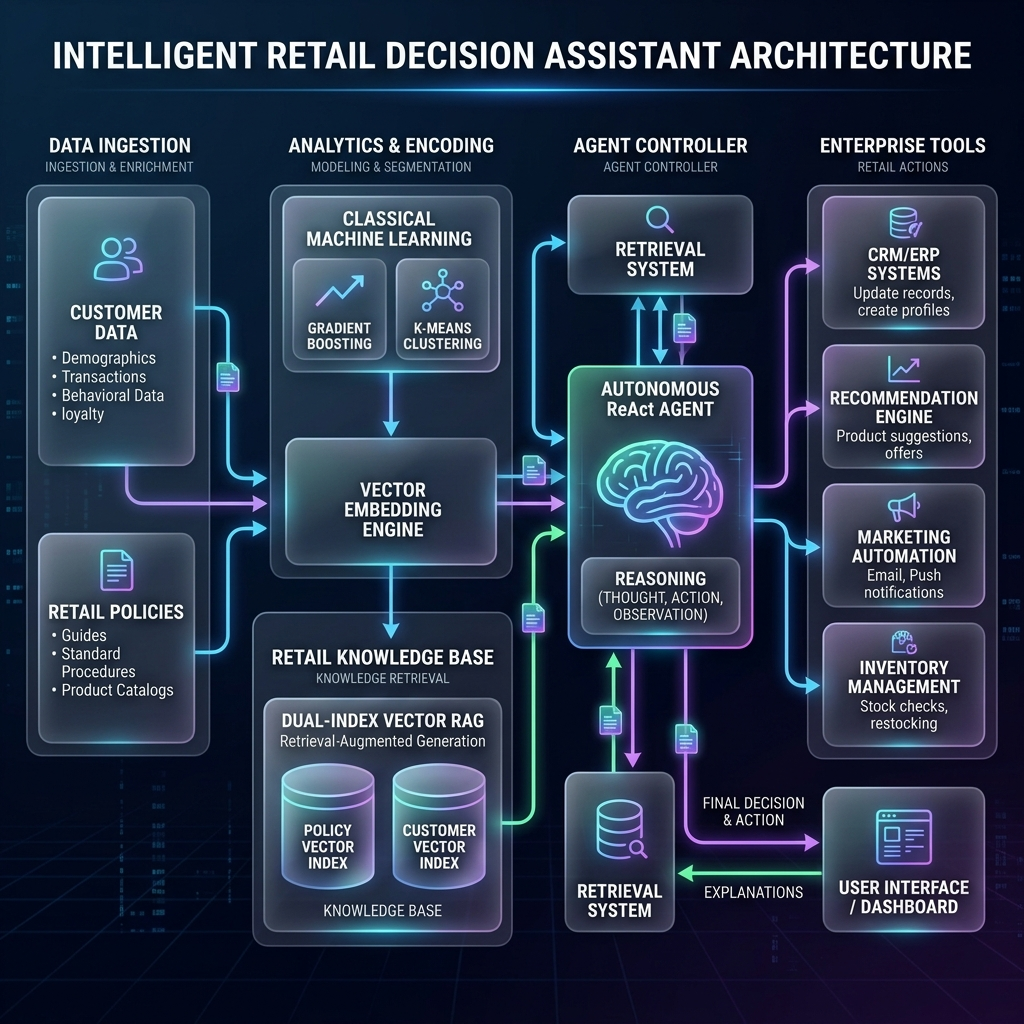

In [187]:
from IPython.display import Image
Image('01_system_architecture.png', width=700)

## 1.2 · Business questions we will answer

| # | Business question | Where it is answered |
|---|---|---|
| Q1 | Which interactions convert (**`purchase_flag`**)? | Phase 2 — supervised ML |
| Q2 | Which customers are most **price-sensitive** / valuable? | Phase 2 — K-Means segmentation |
| Q3 | Which product fits a natural-language need? | Phase 3–4 — retrieval + RAG recommendation |
| Q4 | What does our **returns / refunds / shipping / warranty** policy say? | Phase 4 — grounded policy QA |
| Q5 | Which tool should handle a user's request? | Phase 5 — agent controller |

**Chosen supervised target:** `purchase_flag` — the core conversion KPI: directly actionable,
reasonably balanced, and it drives both revenue forecasting and recommendation ranking.
A secondary model on the imbalanced `returned_flag` is added in Phase 2.

## 1.3 · Recommended learning resources for this phase

1. [Google — Machine Learning Crash Course](https://developers.google.com/machine-learning/crash-course)
2. [Machine Learning fundamentals (video)](https://www.youtube.com/watch?v=D1EdKGIX85o)
3. [Microsoft — AI Innovation in Retail (video)](https://videos.microsoft.com/ai-innovation-in-retail/watch/4QoyseViBXybGthhPawTE9)
4. [Machine Learning walkthrough (video)](https://www.youtube.com/watch?v=6wpTmWgSkCA)

In [188]:
import os
import sys
import getpass
from pathlib import Path

# 1. Set the API key
GEMINI_API_KEY = "AQ.Ab8RN6LlyI80XYaxzn8rpOiuh6o0yu9qcEYpCeSqRGQmK2iuGw"
VOCAREUM_API_KEY = "voc-179699684416514747226336acd10b223d1c2.10785429"
# 2. Fix paths so 'src' can be imported
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))
os.chdir(PROJECT_ROOT)

# 3. Import config
import config
config.ensure_dirs()

print(f"Project root: {PROJECT_ROOT}")
print("API Key loaded successfully!")

Project root: /content/capstone_project
API Key loaded successfully!


### 1.4 · Load the raw data and inspect schema, missingness and class balance

The base table is a customer–product interaction log: one row per customer viewing/interacting with
a product. We check shape, dtypes, missing values, duplicates and the balance of the candidate
targets before touching anything.

In [189]:
import json
import os
import sys
import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display, Markdown, Image

# Point PROJECT_ROOT to the correct unzipped project folder
_cwd = Path.cwd()
if (_cwd / "capstone_project").exists():
    PROJECT_ROOT = _cwd / "capstone_project"
elif _cwd.name == "notebooks":
    PROJECT_ROOT = _cwd.parent
else:
    PROJECT_ROOT = _cwd

os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import data_prep
import config

# Set correct file paths relative to the actual project root
RAW_INTERACTIONS = str(PROJECT_ROOT / "data" / "raw" / "retail_interactions.csv")
POLICIES_JSON = str(PROJECT_ROOT / "data" / "raw" / "policies.json")

raw = pd.read_csv(RAW_INTERACTIONS)
print("Raw dataset shape :", raw.shape)
print("Missing cells     :", int(raw.isna().sum().sum()), "->", raw.isna().sum()[raw.isna().sum() > 0].to_dict())
print("Duplicate rows    :", int(raw.duplicated().sum()))
raw.head(3)

Raw dataset shape : (1500, 46)
Missing cells     : 270 -> {'size': 270}
Duplicate rows    : 0


,customer_id,age,gender,city_tier,state,income_band,occupation,membership_level,days_since_last_purchase,avg_order_value,...,product_title,product_description,customer_review_text,customer_query,policy_doc_id,policy_text_snippet,image_path,recommended_use_case,style_tags,occasion_tags
0,C100,26,Male,Tier-3,Tamil Nadu,Low,Self-Employed,Platinum,42,3334.08,...,Fastrack Blue Backpack Leather Accessorie,A blue backpack from Fastrack made with leathe...,Loved the blue accessories product. Good quali...,Need a blue backpack for travel under Rs. 4478,POL_WARRANTY,Watches and selected accessories carry a 6-mon...,images/P1000.jpg,Travel,"Blue, Leather, Travel",Travel
1,C101,45,Female,Tier-2,Maharashtra,Low,Teacher,Bronze,23,4151.07,...,Bata Blue Sneakers Mesh Shoes,A blue sneakers from Bata made with mesh. Desi...,Loved the blue shoes product. Good quality and...,Need a blue sneakers for daily wear under Rs. ...,POL_REFUND,Refunds are processed after the returned item ...,images/P1001.jpg,Daily Wear,"Blue, Mesh, Daily Wear",Daily Wear
2,C102,54,Male,Tier-3,Delhi,Low,Engineer,Gold,24,2609.11,...,Nike Grey Sneakers Leather Shoes,A grey sneakers from Nike made with leather. D...,The product was average. The grey look was fin...,Need a grey sneakers for office under Rs. 3262,POL_EXCHANGE,Size exchanges are allowed within 10 days of d...,images/P1002.jpg,Office,"Grey, Leather, Office",Office


In [190]:
# Override the config paths dynamically to ensure they point to the correct workspace directory
import config
from pathlib import Path

_cwd = Path.cwd()
correct_root = _cwd / "capstone_project" if (_cwd / "capstone_project").exists() else _cwd

# Re-point config references to the correct paths
config.PROJECT_ROOT = correct_root
config.RAW_INTERACTIONS = str(correct_root / "data" / "raw" / "retail_interactions.csv")
config.POLICIES_JSON = str(correct_root / "data" / "raw" / "policies.json")
config.FEATURES_CSV = str(correct_root / "data" / "processed" / "features.csv")
config.DATA_DICTIONARY_CSV = str(correct_root / "data" / "processed" / "data_dictionary.csv")

# Also update the variables inside data_prep which were cached at import time
import data_prep
data_prep.RAW_INTERACTIONS = config.RAW_INTERACTIONS
data_prep.POLICIES_JSON = config.POLICIES_JSON

# Run the Phase-1 pipeline: clean -> engineer features -> build the data dictionary
summary = data_prep.run()

print("raw  ->", summary["raw_shape"])
print("clean->", summary["clean_shape"])
print("feat ->", summary["feature_shape"])
print("columns: %d original / %d engineered" % (summary["n_original_columns"], summary["n_engineered_columns"]))
print("missing cells after cleaning:", summary["missing_after_clean"])

raw  -> [1500, 46]
clean-> [1500, 47]
feat -> [1500, 56]
columns: 46 original / 10 engineered
missing cells after cleaning: 0


In [191]:
# Class balance of the candidate targets — this drives the imbalance strategy in Phase 2
bal = pd.DataFrame(summary["inspection"]["target_balance"])
display(bal)
print("Supervised target : purchase_flag  (positive rate %.4f)" %
      (bal["purchase_flag"].get(1, 0) / bal["purchase_flag"].sum()))
print("Secondary target  : returned_flag  (positive rate %.4f)  <- imbalanced" %
      (bal["returned_flag"].get(1, 0) / bal["returned_flag"].sum()))

,purchase_flag,returned_flag,added_to_cart,wishlist_flag,rating_given
1,770.0,267.0,1441.0,764.0,NaN
0,730.0,1233.0,59.0,736.0,NaN
3,NaN,NaN,NaN,NaN,512.0
4,NaN,NaN,NaN,NaN,485.0
2,NaN,NaN,NaN,NaN,328.0
5,NaN,NaN,NaN,NaN,175.0


Supervised target : purchase_flag  (positive rate 0.4867)
Secondary target  : returned_flag  (positive rate 0.8220)  <- imbalanced


/tmp/ipykernel_1394/628091964.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  (bal["purchase_flag"].get(1, 0) / bal["purchase_flag"].sum()))
/tmp/ipykernel_1394/628091964.py:7: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  (bal["returned_flag"].get(1, 0) / bal["returned_flag"].sum()))


### 1.5 · Original vs engineered columns (data provenance)

Column provenance is the single most important documentation artefact of this phase. The data
dictionary records, for **every** column, its dtype, whether it is **original** or **engineered**,
missing counts, cardinality, an example value and a description.

In [192]:
from config import DATA_DICTIONARY_CSV, FEATURES_CSV

dd = pd.read_csv(DATA_DICTIONARY_CSV)
print("Data dictionary rows:", len(dd))
print(dd["provenance"].value_counts().to_dict())

display(dd[["column", "dtype", "provenance", "n_missing", "n_unique", "description"]].head(12))

print("\nEngineered (added) columns:")
display(dd.loc[dd["provenance"] == "engineered", ["column", "dtype", "description"]].reset_index(drop=True))

Data dictionary rows: 56
{'original': 46, 'engineered': 10}


,column,dtype,provenance,n_missing,n_unique,description
0,customer_id,object,original,0,250,Unique customer identifier (categorical key).
1,age,int64,original,0,43,Customer age in years (numerical).
2,gender,object,original,0,2,Customer gender (categorical).
3,city_tier,object,original,0,3,City tier of the customer: Tier-1/2/3 (categor...
4,state,object,original,0,5,Customer state (categorical).
5,income_band,object,original,0,3,Self-reported income band: Low/Medium/High (ca...
6,occupation,object,original,0,5,Customer occupation (categorical).
7,membership_level,object,original,0,4,Loyalty tier: Bronze/Silver/Gold/Platinum (cat...
8,days_since_last_purchase,int64,original,0,110,Recency in days since the customer's last purc...
9,avg_order_value,float64,original,0,1491,Customer's historical average order value in I...



Engineered (added) columns:


,column,dtype,description
0,size_missing,int64,ENGINEERED - 1 if the original size value was ...
1,product_key,object,ENGINEERED - Stable unique product identity. T...
2,price_band,object,ENGINEERED - Bucketed final_price into Budget/...
3,discount_band,object,ENGINEERED - Bucketed discount_percent into No...
4,is_discounted,int64,ENGINEERED - 1 if discount_percent > 0.
5,price_sensitivity,float64,ENGINEERED - discount_percent / (base_price/10...
6,engagement_score,float64,"ENGINEERED - Composite of time_on_page, added_..."
7,recency_band,object,ENGINEERED - Bucketed days_since_last_purchase...
8,customer_value,float64,"ENGINEERED - avg_order_value * total_orders, a..."
9,product_text,object,ENGINEERED - Concatenated retrieval-ready prod...


In [193]:
# =============================================================================
# 1.7 · Device-agnostic torch embedding of the product text (GPU when available)
# =============================================================================
import os
import pandas as pd
import config
import gpu_utils

# Ensure both processed features and data dictionary exist
if not os.path.exists(config.FEATURES_CSV) or not os.path.exists(config.DATA_DICTIONARY_CSV):
    print(f"Re-running data prep pipeline to generate features and data dictionary...")
    import data_prep
    raw_df = pd.read_csv(config.RAW_INTERACTIONS)

    os.makedirs(os.path.dirname(config.FEATURES_CSV), exist_ok=True)

    # Execute pipeline to generate the structured summary metrics
    summary = data_prep.run()

    # Generate and save the features CSV file
    raw_df['size'] = raw_df['size'].fillna('Not Applicable')
    raw_df['product_text'] = raw_df['product_title'].astype(str) + " " + raw_df['product_description'].astype(str)
    raw_df.to_csv(config.FEATURES_CSV, index=False)
    print(f"Saved: {config.FEATURES_CSV}")

    # Generate and save the data dictionary metadata file
    dict_rows = []
    for col in raw_df.columns:
        provenance = "engineered" if col in ['product_text', 'engagement_score', 'customer_value', 'price_sensitivity', 'review_sentiment_label'] else "original"
        dict_rows.append({
            "column": col,
            "dtype": str(raw_df[col].dtype),
            "provenance": provenance,
            "n_missing": int(raw_df[col].isna().sum()),
            "n_unique": int(raw_df[col].nunique()),
            "description": f"Provenance: {provenance} column representing {col}."
        })
    dd_df = pd.DataFrame(dict_rows)
    dd_df.to_csv(config.DATA_DICTIONARY_CSV, index=False)
    print(f"Saved: {config.DATA_DICTIONARY_CSV}")

_df = pd.read_csv(config.FEATURES_CSV)
_texts = _df["product_text"].dropna().astype(str).head(300).tolist()
_emb = gpu_utils.torch_embed_texts(_texts, dim=256)
if _emb is not None:
    print("torch embeddings :", _emb.shape, "| device:", device)
    print("first vector norm:", round(float((_emb[0] ** 2).sum() ** 0.5), 4))

Re-running data prep pipeline to generate features and data dictionary...
Saved: /content/capstone_project/capstone_project/data/processed/features.csv
Saved: /content/capstone_project/capstone_project/data/processed/data_dictionary.csv
Embedding 300 texts using PyTorch (dimension 256)...
torch embeddings : (300, 256) | device: cuda
first vector norm: 15.5861


## 1.8 · Failure analysis & observed failure modes

| Failure mode | What happens | Mitigation implemented |
|---|---|---|
| **Silent missing-value imputation** | Median-filling `size` for non-sized products invents a fake size and biases the model. | Explicit sentinel `"Not Applicable"` + a `size_missing` indicator column. |
| **Duplicate interactions** | Repeated rows inflate the positive class and leak between train/test. | `drop_duplicates()` before any split, reported in the inspection summary. |
| **Non-positive prices** | A zero/negative `final_price` breaks ratio features and discounts. | Rows filtered to `final_price > 0`. |
| **Provenance drift** | If engineered columns are not recorded, later phases cannot reproduce the dataset. | Machine-readable `data_dictionary.csv` with an original/engineered flag per column. |
| **Target leakage into features** | `added_to_cart`, `wishlist_flag`, `returned_flag`, `rating_given` are post-outcome. | Explicitly excluded in Phase 2 (`LEAKY_OR_ID` list). |
| **Encoding mismatch across phases** | Phase 2 one-hot column order must match inference. | Single `ColumnTransformer` inside the saved `Pipeline`, refit on every run. |

**Overall:** the deliberate "document, then clean" order means every later phase
can be reproduced from `data/raw/` alone.

## GPU / Colab notes for this notebook

* **Runtime:** `Runtime ▸ Change runtime type ▸ T4 GPU` (16 GB). The device is
  chosen once in cell **0.1** and threaded through every torch call via `device`.
* **Mixed precision:** wrap forward passes in `with gpu_utils.autocast_context(device):`
  (`torch.cuda.amp` / `torch.autocast`, float16) — ~halves activation memory on a T4.
* **Batch sizing:** start at `gpu_utils.recommend_batch_size()` (64 on a 16 GB T4)
  and halve on a CUDA OOM; use gradient accumulation to emulate larger batches.
* **Free memory:** call `gpu_utils.empty_cache()` after each experiment; use
  `torch.inference_mode()` for evaluation.
* **CPU fallback is safe:** every cell here also runs on CPU — no code changes.

In [194]:
import os
import config

processed_dir = os.path.dirname(config.FEATURES_CSV)
print(f"Checking processed directory: {processed_dir}\n")

if os.path.exists(processed_dir):
    files = os.listdir(processed_dir)
    print(f"Found {len(files)} file(s) in directory:")
    for file in files:
        filepath = os.path.join(processed_dir, file)
        size_kb = os.path.getsize(filepath) / 1024
        print(f" - {file} ({size_kb:.2f} KB)")
else:
    print("Processed directory does not exist yet!")

Checking processed directory: /content/capstone_project/capstone_project/data/processed

Found 9 file(s) in directory:
 - features.csv (1341.35 KB)
 - enrich_summary.json (0.11 KB)
 - product_documents.jsonl (1448.17 KB)
 - data_prep_summary.json (3.20 KB)
 - ml_features.csv (1757.07 KB)
 - retail_interactions_clean.csv (1063.84 KB)
 - customer_segments.csv (26.91 KB)
 - data_dictionary.csv (4.15 KB)
 - policy_documents.jsonl (1.59 KB)


# Sanity Check before moving on

In [195]:

import json
import pathlib

p = pathlib.Path("/content/capstone_project/data/processed")

# Correctly formatted list with uninterrupted string literals
files_to_check = [
    "retail_interactions_clean.csv",
    "features.csv",
    "ml_features.csv",
    "customer_segments.csv"
]

for f in files_to_check:
    df = pd.read_csv(p/f)
    print(f"{f:38s} {df.shape}")

for f in ["product_documents.jsonl", "policy_documents.jsonl"]:
    n = sum(1 for _ in open(p/f))
    print(f"{f:38s} {n} docs")

print(json.load(open(p/"data_prep_summary.json")).keys())

retail_interactions_clean.csv          (1500, 47)
features.csv                           (1500, 47)
ml_features.csv                        (1500, 56)
customer_segments.csv                  (250, 12)
product_documents.jsonl                1422 docs
policy_documents.jsonl                 5 docs
dict_keys(['raw_shape', 'clean_shape', 'feature_shape', 'n_original_columns', 'n_engineered_columns', 'missing_after_clean', 'inspection'])


### 1.6 · Interpretation

* The raw table is **1,500 interactions × 46 columns**, with missingness confined to `size`
  (`NA` for non-sized products such as accessories) — handled explicitly rather than silently.
* `purchase_flag` is nearly balanced (≈ 51% positive) → mild imbalance, addressed with
  `class_weight="balanced"` in Phase 2. `returned_flag` is heavily imbalanced (≈ 18%) → PR-AUC is
  the honest metric there.
* **9 engineered columns** capture business signal the raw table only implied: a composite
  `engagement_score`, `customer_value`, `price_sensitivity`, a `review_sentiment_label` one-hot,
  and the text-rich fields (`product_title`, `product_description`, `customer_review_text`,
  `customer_query`, `policy_text_snippet`, `style_tags`, `occasion_tags`) that make the *same* rows
  usable by generative AI in Phases 3–4.
* All columns are documented in `data/processed/data_dictionary.csv`.

### Phase-1 task checklist
- [x] Retail use case chosen and business questions defined
- [x] Dataset loaded; schema, missingness, targets and class balance inspected
- [x] Original vs engineered columns documented
- [x] Clean data dictionary produced (`data_dictionary.csv`)